## Lab 5 - Logistic Regression and K-Nearest Neighbors

This notebook has two parts:

- **Part A - Logistic Regression:** completed in-class walkthrough using the real Breast Cancer Wisconsin dataset.
- **In-class KNN demonstration:** a small 2-feature example showing distance, neighbours and voting.
- **Part B - KNN:** student coding exercise using the **same Breast Cancer dataset**.

### Submission
Complete all TODO cells in Part B and submit this notebook with the outputs visible.


# Part A - Logistic Regression

We will learn Logistic Regression through an actual classification problem rather than a synthetic example.

The dataset contains measurements extracted from digitized images of breast-mass cell nuclei. The original scikit-learn target uses:

- `0 = malignant`
- `1 = benign`

For this lab we remap the target to:

- **`1 = malignant`**
- **`0 = benign`**

This makes the positive class the clinically important malignant class.


## A1 - Load and inspect the real dataset


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)

X = data.data.copy()

# Original target: 0 = malignant, 1 = benign
# Remap so that the positive class is malignant.
y = 1 - data.target

print("Dataset shape:", X.shape)
print("Number of input features:", X.shape[1])
print("\nOriginal target names:", data.target_names)
print("\nFirst 10 feature names:")
print(list(X.columns[:10]))

class_counts = pd.Series(y).value_counts().sort_index()
print("\nRemapped class counts:")
print(pd.DataFrame({
    "Class": ["Benign (0)", "Malignant (1)"],
    "Count": [class_counts.loc[0], class_counts.loc[1]]
}))


Dataset shape: (569, 30)
Number of input features: 30

Original target names: ['malignant' 'benign']

First 10 feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension']

Remapped class counts:
           Class  Count
0     Benign (0)    357
1  Malignant (1)    212


### What is the prediction task?

Each row contains **30 numerical input features**.  
The target is not a continuous quantity such as price. It is one of two classes:

- 0 = benign
- 1 = malignant

Therefore, this is a **binary classification** problem.


## A2 - Look at two actual features and the two classes


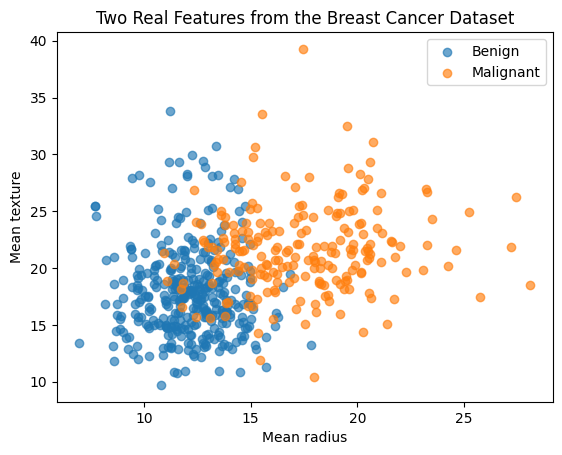

In [ ]:
plot_df = X[["mean radius", "mean texture"]].copy()
plot_df["target"] = y.values

for cls, label in [(0, "Benign"), (1, "Malignant")]:
    subset = plot_df[plot_df["target"] == cls]
    plt.scatter(
        subset["mean radius"],
        subset["mean texture"],
        alpha=0.65,
        label=label
    )

plt.xlabel("Mean radius")
plt.ylabel("Mean texture")
plt.title("Two Real Features from the Breast Cancer Dataset")
plt.legend()
plt.show()


The two classes show different tendencies, but they also **overlap**.  
A classifier therefore needs to learn a decision rule from all available information rather than use one simple cut-off on a single feature.


## A3 - Prepare training and test data


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest class proportions:")
print(y_test.value_counts(normalize=True).sort_index())


Training shape: (455, 30)
Test shape: (114, 30)

Training class proportions:
target
0    0.626374
1    0.373626
Name: proportion, dtype: float64

Test class proportions:
target
0    0.631579
1    0.368421
Name: proportion, dtype: float64


### Why use `stratify=y`?

For classification, we want the training and test sets to keep approximately the same class proportions as the original dataset.  
`stratify=y` helps preserve that balance.


## A4 - Standardize the input features


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn mean and standard deviation ONLY from the training data.
X_train_scaled = scaler.fit_transform(X_train)

# Reuse the same training statistics for the test data.
X_test_scaled = scaler.transform(X_test)

print("First five standardized values of the first training observation:")
print(X_train_scaled[0, :5])


First five standardized values of the first training observation:
[ 0.51855873  0.89182579  0.4246317   0.38392544 -0.97474371]


The 30 measurements use different numerical scales. Standardization places them on comparable scales.

The important rule is:

> **Learn preprocessing statistics from the training data only, then apply the same transformation to unseen/test data.**


## A5 - Train a Logistic Regression model


In [ ]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=2000)
log_model.fit(X_train_scaled, y_train)

print("Classes used by the model:", log_model.classes_)
print("Number of learned coefficients:", log_model.coef_.shape[1])


Classes used by the model: [0 1]
Number of learned coefficients: 30


/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

## A6 - What does Logistic Regression actually calculate?

Logistic Regression first calculates a **linear score**:

\[
z = \theta_0 + \theta_1x_1 + \theta_2x_2 + \cdots + \theta_nx_n
\]

The value of \(z\) can be any real number.

It then applies the **sigmoid function**:

\[
p = \frac{1}{1+e^{-z}}
\]

which converts the score to a value between 0 and 1.

For this lab, that probability is:

\[
p = P(\text{malignant}=1 \mid X)
\]

We will verify this with a real test observation.


In [ ]:
# Take the first real test observation.
sample_scaled = X_test_scaled[0].reshape(1, -1)

# Linear score z produced by the fitted model.
z = log_model.decision_function(sample_scaled)[0]

# Apply the sigmoid manually.
p_manual = 1 / (1 + np.exp(-z))

# Probability returned by sklearn for class 1 = malignant.
p_sklearn = log_model.predict_proba(sample_scaled)[0, 1]

actual_class = int(y_test.iloc[0])

print("Actual class:", actual_class, "(1 = malignant, 0 = benign)")
print("Linear score z:", z)
print("Manual sigmoid(z):", p_manual)
print("sklearn P(malignant):", p_sklearn)


Actual class: 0 (1 = malignant, 0 = benign)
Linear score z: -7.916432514318083
Manual sigmoid(z): 0.0003645681159627872
sklearn P(malignant): 0.0003645681159627872


The manually calculated sigmoid value and `predict_proba()` should match closely.

This demonstrates the chain:

**input features → linear score \(z\) → sigmoid → malignant probability**


## A7 - Convert probability to a class


In [ ]:
threshold = 0.5

predicted_class_manual = int(p_sklearn >= threshold)
predicted_class_sklearn = int(log_model.predict(sample_scaled)[0])

print("P(malignant):", p_sklearn)
print("Threshold:", threshold)
print("Manual class decision:", predicted_class_manual)
print("sklearn predict():", predicted_class_sklearn)


P(malignant): 0.0003645681159627872
Threshold: 0.5
Manual class decision: 0
sklearn predict(): 0


Using the default threshold:

- if \(p \ge 0.5\), predict **class 1 (malignant)**
- if \(p < 0.5\), predict **class 0 (benign)**

So `predict_proba()` gives the probability, while `predict()` gives the final class decision.


## A8 - Inspect probabilities from actual test cases


In [ ]:
y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]
y_pred_log = log_model.predict(X_test_scaled)

log_results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "P(Malignant)": y_prob_log,
    "Predicted": y_pred_log
})

log_results.head(12)


/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,Actual,P(Malignant),Predicted
0,0,0.000365,0
1,1,1.000000,1
2,0,0.042568,0
3,1,0.576187,1
4,0,0.509155,1
5,0,0.000616,0
6,1,0.761534,1
7,0,0.001012,0
8,0,0.000569,0
9,0,0.010768,0


Look for examples where the probability is close to 0 or 1, and also examples closer to 0.5.

A probability near 0.5 means the model is less decisive than when the probability is very close to 0 or 1.


## A9 - Evaluate the complete Logistic Regression classifier


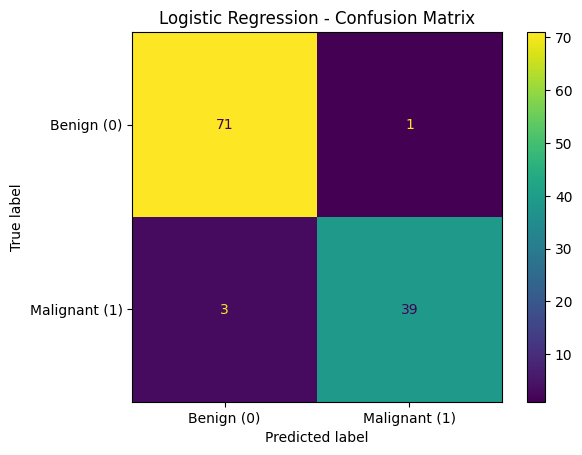

,Accuracy,Precision,Recall,F1
Logistic Regression,0.964912,0.975,0.928571,0.95122


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cm_log = confusion_matrix(y_test, y_pred_log)

ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=["Benign (0)", "Malignant (1)"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

lr_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_log),
    "Precision": precision_score(y_test, y_pred_log),
    "Recall": recall_score(y_test, y_pred_log),
    "F1": f1_score(y_test, y_pred_log)
}

pd.DataFrame([lr_metrics], index=["Logistic Regression"])


### Interpreting the metrics

Because **malignant = 1**:

- **Precision:** Of the cases predicted malignant, how many were actually malignant?
- **Recall:** Of the actual malignant cases, how many did the model identify?
- **F1-score:** Balances precision and recall.
- **Accuracy:** Fraction of all test cases classified correctly.

This completes a full working Logistic Regression pipeline on the real dataset.


# In-class Demonstration - How KNN Makes a Prediction

Before Part B, this small 2-feature dataset is used to show exactly how KNN makes a prediction.

Unlike Logistic Regression, standard KNN does **not** learn coefficients by minimizing a differentiable objective function. It predicts by:

1. measuring distance to stored training observations,
2. selecting the \(k\) nearest observations,
3. letting their class labels vote.


## Example 1 - A tiny labelled dataset

Here, each row has only two features so we can see the geometry.

- Class 0 points are concentrated near the lower-left region.
- Class 1 points are concentrated near the upper-right region.
- The new point is deliberately placed between the two groups.


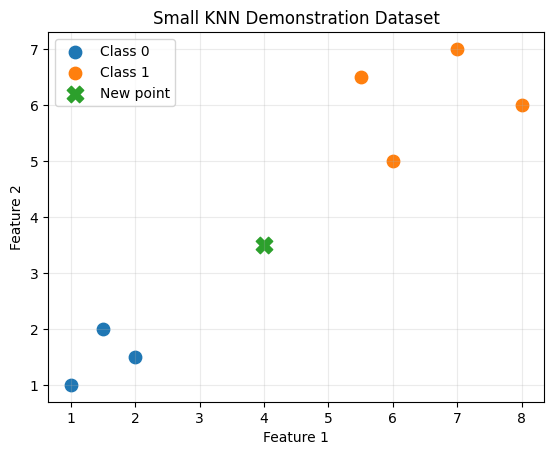

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_small = np.array([
    [1.0, 1.0],
    [1.5, 2.0],
    [2.0, 1.5],
    [6.0, 5.0],
    [7.0, 7.0],
    [8.0, 6.0],
    [5.5, 6.5]
])

y_small = np.array([0, 0, 0, 1, 1, 1, 1])

new_point = np.array([4.0, 3.5])

for cls, label in [(0, "Class 0"), (1, "Class 1")]:
    points = X_small[y_small == cls]
    plt.scatter(points[:, 0], points[:, 1], s=80, label=label)

plt.scatter(new_point[0], new_point[1], s=140, marker="X", label="New point")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Small KNN Demonstration Dataset")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


## Example 2 - Calculate Euclidean distances

For a training point \(x\) and a new point \(q\),

\[
d(x,q)=\sqrt{(x_1-q_1)^2+(x_2-q_2)^2}
\]

With more features, we simply continue the same sum over all feature dimensions.


In [ ]:
distances = np.sqrt(np.sum((X_small - new_point) ** 2, axis=1))

distance_table = pd.DataFrame({
    "Feature 1": X_small[:, 0],
    "Feature 2": X_small[:, 1],
    "Class": y_small,
    "Distance to new point": distances
}).sort_values("Distance to new point")

distance_table


,Feature 1,Feature 2,Class,Distance to new point
3,6.0,5.0,1,2.500000
2,2.0,1.5,0,2.828427
1,1.5,2.0,0,2.915476
6,5.5,6.5,1,3.354102
0,1.0,1.0,0,3.905125
4,7.0,7.0,1,4.609772
5,8.0,6.0,1,4.716991


Read the distance table from the smallest distance upward. Those rows are the nearest neighbours.

For this new point:

- the closest neighbour belongs to **Class 1**,
- but the three closest neighbours contain **one Class 1 and two Class 0** observations.

Therefore, changing \(k\) can change the final prediction.


## Example 3 - Let sklearn perform the same neighbour search


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

for k in [1, 3, 5]:
    knn_example = KNeighborsClassifier(n_neighbors=k)
    knn_example.fit(X_small, y_small)
    prediction = knn_example.predict(new_point.reshape(1, -1))[0]

    neighbour_distances, neighbour_indices = knn_example.kneighbors(
        new_point.reshape(1, -1)
    )

    neighbour_classes = y_small[neighbour_indices[0]]

    print(
        f"k={k}: neighbours={neighbour_classes.tolist()} "
        f"-> predicted class={prediction}"
    )


k=1: neighbours=[1] -> predicted class=1
k=3: neighbours=[1, 0, 0] -> predicted class=0
k=5: neighbours=[1, 0, 0, 1, 0] -> predicted class=0


### Effect of k on the prediction

For \(k=1\), only the closest observation decides the class.

For \(k=3\), three nearby observations vote. In this example, the majority can be different from the single closest neighbour.

This is the main role of \(k\):

- **small \(k\)** → very local and flexible; sensitive to individual samples and noise,
- **larger \(k\)** → smoother and more stable; too large can ignore useful local structure.

There is no derivative with respect to \(k\). \(k\) is a **hyperparameter** that we choose experimentally.


# Logistic Regression vs KNN - What Is the Real Difference?

Both methods can solve the same binary classification problem, but they make decisions in fundamentally different ways.

| Aspect | Logistic Regression | KNN |
|---|---|---|
| Main idea | Learn a global mathematical relationship | Use similarity to nearby stored examples |
| What is learned | Coefficients \(\theta\) | No global coefficient equation |
| Prediction | Linear score → sigmoid → probability → class | Distance → nearest neighbours → vote |
| Decision boundary | Linear by default | Can be highly nonlinear |
| Training | Numerical optimization | Mainly stores/prepares training data |
| Prediction cost | Usually fast | Can be slower as training data grows |
| Feature scaling | Important | **Very important** because distance is used |
| High dimensions | Often works well with regularization | Can degrade because distances become less informative |
| Interpretability | Coefficients/probabilities can be interpreted | Decision is based on individual neighbours |


## When would you prefer Logistic Regression?

Logistic Regression is a good first choice when:

- the relationship between the features and the class is reasonably represented by a **linear decision boundary**,
- you want an explicit **probability of the positive class**,
- you want a compact model with learned coefficients,
- interpretation of feature effects is useful,
- the dataset is large enough that repeatedly searching all training samples would be expensive,
- the feature space is moderate or high dimensional.

**Example scenarios:** disease-risk classification, loan default prediction, customer churn, pass/fail prediction, spam detection with suitable features.


## When would you prefer KNN?

KNN is attractive when:

- the dataset is **small or medium-sized**,
- observations of the same class tend to occur in **local neighbourhoods**,
- the decision boundary may be irregular or nonlinear,
- the numerical features have a meaningful distance interpretation,
- a simple instance-based baseline is useful.

**Example scenarios:** small pattern-recognition problems, classifying a new sensor sample from similar historical samples, simple image/shape features, or local similarity-based classification.

KNN becomes less attractive when the training set is extremely large or the number of features is very high, because neighbour search becomes expensive and distance can become less informative.


## A useful final sentence for students

> **Logistic Regression asks:** “What global equation best separates the classes?”

> **KNN asks:** “Which known training examples are most similar to this new example?”

Now move to Part B and apply KNN to the same Breast Cancer dataset used for Logistic Regression.


# Part B - Student Exercise: Apply KNN to the Same Dataset

KNN will be explained separately during the laboratory session.

For Part B, **start again from the raw dataset** and complete the preprocessing and KNN workflow yourself.

Do not reuse the already prepared `X_train_scaled` and `X_test_scaled` from Part A.  
Use the new variable names provided below so that your Part B work is independent and visible.


## B1 - Reload the dataset and prepare X and y


In [8]:
# TODO 1
# 1. Load the Breast Cancer dataset with as_frame=True.
# 2. Create X_knn using all input features.
# 3. Remap the target so that malignant = 1 and benign = 0.
# 4. Print the shape and class counts.

from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)

X_knn = cancer.data
y_knn = cancer.target

print("X_knn shape:", X_knn.shape)
print("y_knn shape:", y_knn.shape)
print("\nClass counts (1 = malignant, 0 = benign):")
print(y_knn.value_counts())


X_knn shape: (569, 30)
y_knn shape: (569,)

Class counts (1 = malignant, 0 = benign):
target
1    357
0    212
Name: count, dtype: int64


## B2 - Create a stratified train-test split


In [9]:
# TODO 2
# Split X_knn and y_knn:
# - test_size = 0.20
# - random_state = 42
# - stratify = y_knn
#
# Use these variable names:
# X_train_knn, X_test_knn, y_train_knn, y_test_knn

from sklearn.model_selection import train_test_split

X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(
    X_knn, y_knn, test_size=0.20, random_state=42, stratify=y_knn
)

print("X_train_knn shape:", X_train_knn.shape)
print("X_test_knn shape: ", X_test_knn.shape)


X_train_knn shape: (455, 30)
X_test_knn shape:  (114, 30)


## B3 - Standardize the features correctly


In [10]:
# TODO 3
# 1. Create a StandardScaler.
# 2. Fit it ONLY using X_train_knn.
# 3. Transform both X_train_knn and X_test_knn.
#
# Use:
# X_train_knn_scaled
# X_test_knn_scaled

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_knn_scaled = scaler.fit_transform(X_train_knn)

X_test_knn_scaled = scaler.transform(X_test_knn)

print("X_train_knn_scaled shape:", X_train_knn_scaled.shape)
print("X_test_knn_scaled shape: ", X_test_knn_scaled.shape)


X_train_knn_scaled shape: (455, 30)
X_test_knn_scaled shape:  (114, 30)


### Reminder for KNN

KNN uses distances between observations. If the features are on very different numerical scales, large-scale features can dominate the distance calculation.

Therefore, standardization is especially important before KNN.


## B4 - Train KNN with k = 5


In [11]:
# TODO 4
# 1. Create KNeighborsClassifier with n_neighbors = 5.
# 2. Fit it using the standardized training data.
# 3. Predict the test set.
#
# Store predictions as y_pred_knn5.

from sklearn.neighbors import KNeighborsClassifier

knn_5 = KNeighborsClassifier(n_neighbors=5)

knn_5.fit(X_train_knn_scaled, y_train_knn)

y_pred_knn5 = knn_5.predict(X_test_knn_scaled)

print("First 10 predictions:", y_pred_knn5[:10])


First 10 predictions: [0 1 0 0 0 1 1 0 0 0]


## B5 - Evaluate KNN


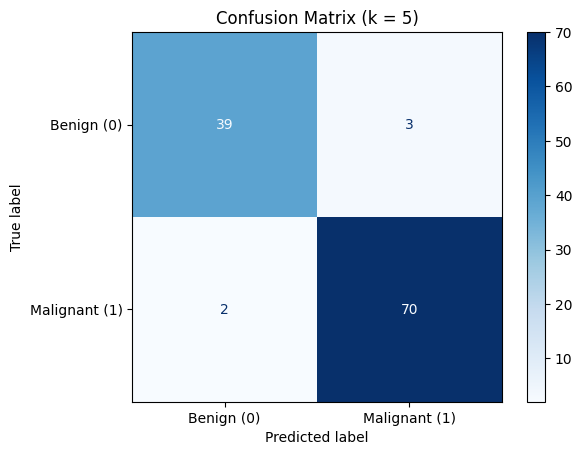

,Accuracy,Precision,Recall,F1-score
0,0.95614,0.958904,0.972222,0.965517


In [12]:
# TODO 5
# 1. Create and display the confusion matrix.
# 2. Calculate Accuracy, Precision, Recall and F1-score.
# 3. Store the four values in a dictionary named knn5_metrics.
# 4. Display the metrics as a one-row DataFrame.

import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(y_test_knn, y_pred_knn5)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign (0)', 'Malignant (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (k = 5)")
plt.show()

acc = accuracy_score(y_test_knn, y_pred_knn5)
prec = precision_score(y_test_knn, y_pred_knn5)
rec = recall_score(y_test_knn, y_pred_knn5)
f1 = f1_score(y_test_knn, y_pred_knn5)

knn5_metrics = {
    'Accuracy': acc,
    'Precision': prec,
    'Recall': rec,
    'F1-score': f1
}

df_knn5_metrics = pd.DataFrame([knn5_metrics])
display(df_knn5_metrics)


## B6 - Investigate different values of k


In [13]:
# TODO 6
# Try these odd values of k:
k_values = [1, 3, 5, 7, 9, 11, 15]

# For each k:
# - train KNN
# - predict the same test set
# - calculate Accuracy and F1
# - append the results to a list
#
# Convert the list to a DataFrame named k_results and display it.

k_values = [1, 3, 5, 7, 9, 11, 15]

results_list = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn_scaled, y_train_knn)

    y_pred = knn.predict(X_test_knn_scaled)

    acc = accuracy_score(y_test_knn, y_pred)
    f1 = f1_score(y_test_knn, y_pred)

    results_list.append({
        'k': k,
        'Accuracy': acc,
        'F1-score': f1
    })

k_results = pd.DataFrame(results_list)
display(k_results)

,k,Accuracy,F1-score
0,1,0.938596,0.951049
1,3,0.982456,0.986301
2,5,0.956140,0.965517
3,7,0.973684,0.979592
4,9,0.973684,0.979592
5,11,0.973684,0.979592
6,15,0.973684,0.979592


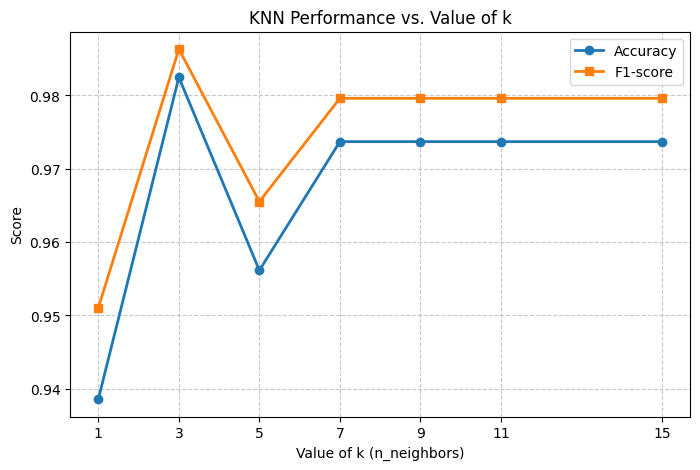

In [14]:
# TODO 7
# Plot k against Accuracy and F1 using the k_results table.
# Include axis labels, title and legend.

# YOUR CODE HERE
plt.figure(figsize=(8, 5))

# Plot Accuracy and F1 lines
plt.plot(k_results['k'], k_results['Accuracy'], marker='o', label='Accuracy', linewidth=2)
plt.plot(k_results['k'], k_results['F1-score'], marker='s', label='F1-score', linewidth=2)

# Set axis labels and title
plt.xlabel('Value of k (n_neighbors)')
plt.ylabel('Score')
plt.title('KNN Performance vs. Value of k')

# Add grid, x-ticks, and legend
plt.xticks(k_results['k'])
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()


Do not assume that the smallest or largest value of \(k\) is automatically best.  
Use the experimental results to see how the neighbourhood size changes classifier behaviour.


## B7 - Final Model Comparison

Both Logistic Regression and KNN have now been applied to the **same classification problem** using the same target definition and train-test split.

Compare the performance of the two models. At minimum, compare their **test accuracy**. You may also use precision, recall, F1-score, confusion matrices, or any other results already produced in the notebook if they help you explain the difference.

**Present your findings in any clear form you prefer.** For example, you may use a table, chart, printed summary, short Markdown explanation, or a combination of these. There is no required presentation format.

Your comparison should make it clear which model performed better according to the evidence you chose to present. Also note if different metrics lead to different conclusions.


=== Performance Comparison Table ===


,Model,Accuracy,Precision,Recall,F1-score
0,KNN (k=5),0.956140,0.958904,0.972222,0.965517
1,Logistic Regression,0.982456,0.986111,0.986111,0.986111


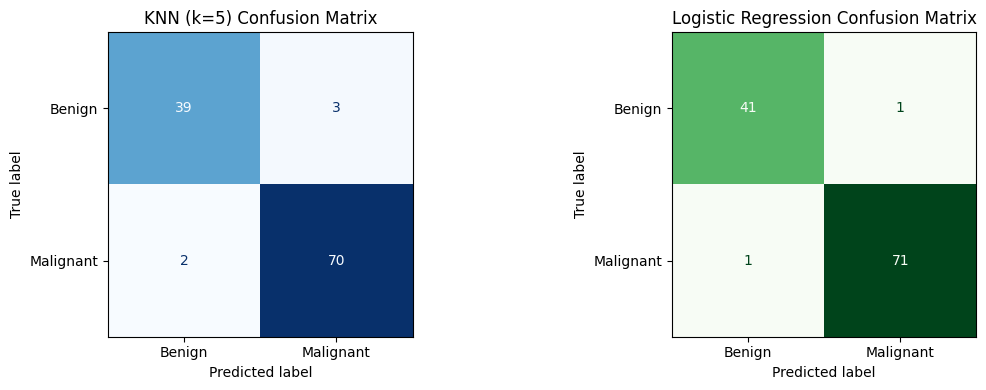

In [15]:
# TODO 8 - Final comparison
# Compare Logistic Regression and KNN on the same test data.
# At minimum, compare test accuracy.
# You may also include Precision, Recall, F1-score, confusion matrices,
# or results from the k experiment if they help support your findings.
#
# Present the findings in any clear form you prefer:
# table, chart, printed summary, Markdown explanation, or a combination.
# There is no required format.

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
)

log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_knn_scaled, y_train_knn)
y_pred_logreg = log_reg.predict(X_test_knn_scaled)

logreg_metrics = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test_knn, y_pred_logreg),
    'Precision': precision_score(y_test_knn, y_pred_logreg),
    'Recall': recall_score(y_test_knn, y_pred_logreg),
    'F1-score': f1_score(y_test_knn, y_pred_logreg)
}

knn5_metrics_formatted = {
    'Model': 'KNN (k=5)',
    'Accuracy': accuracy_score(y_test_knn, y_pred_knn5),
    'Precision': precision_score(y_test_knn, y_pred_knn5),
    'Recall': recall_score(y_test_knn, y_pred_knn5),
    'F1-score': f1_score(y_test_knn, y_pred_knn5)
}

df_comparison = pd.DataFrame([knn5_metrics_formatted, logreg_metrics])
print("=== Performance Comparison Table ===")
display(df_comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm_knn = confusion_matrix(y_test_knn, y_pred_knn5)
ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=['Benign', 'Malignant']).plot(
    ax=axes[0], cmap=plt.cm.Blues, colorbar=False
)
axes[0].set_title('KNN (k=5) Confusion Matrix')

cm_logreg = confusion_matrix(y_test_knn, y_pred_logreg)
ConfusionMatrixDisplay(confusion_matrix=cm_logreg, display_labels=['Benign', 'Malignant']).plot(
    ax=axes[1], cmap=plt.cm.Greens, colorbar=False
)
axes[1].set_title('Logistic Regression Confusion Matrix')

plt.tight_layout()
plt.show()


## Submission

Before submitting:

- Complete all Part B TODO cells.
- Include your final Logistic Regression vs KNN comparison in B7.
- Run the notebook from top to bottom.
- Keep all outputs visible.
- Save the file as **REGNO_Lab05.ipynb**.
